## Use this dataset to train a simple linear classifier

In [420]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [421]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt


# Parameters
n_classes = 5
n_features = 10
n_redundant = 2  # Number of redundant features
n_samples_per_class = 1000
random_state = 42

# Load the dataset
df = pd.read_csv("custom_synthetic_dataset_test3.csv")

# Separate features (X) and target labels (y)
X = df.drop(columns=['Class']).values
y = df['Class'].values

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=42)

# Standardize the features (important for neural networks)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


In [422]:
from sklearn.linear_model import LogisticRegression

# Define the Logistic Regression model with a linear decision boundary
model = LogisticRegression(max_iter=1000, multi_class='ovr', solver='lbfgs', random_state=42)

# Train the model
model.fit(X_train, y_train)

# Predict on the test set
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)
# Calculate the accuracy
test_acc = accuracy_score(y_test, y_pred)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.8670


In [423]:
## Get the weights of the linear regression
def sigmoid(x):
    s = 1 /(1 + np.exp(-x))
    return s
print(model.predict_proba(X_train[0:1]))
x = sigmoid(np.dot(X_train[:1], model.coef_.T) + model.intercept_)
print(x / x.sum())

[[1.20967588e-01 7.54719805e-02 1.98835920e-07 3.91262506e-05
  8.03521106e-01]]
[[1.20967588e-01 7.54719805e-02 1.98835920e-07 3.91262506e-05
  8.03521106e-01]]


In [424]:
from sklearn.metrics import confusion_matrix
confusion_matrix(y_test[:1000], y_pred[:1000])

array([[155,  49,   0,   0,  12],
       [ 45, 133,   0,   0,  12],
       [  0,   0, 189,   0,   3],
       [  0,   0,   0, 210,   0],
       [  6,   0,   0,   0, 186]])

## get the indices for the reward function

In [658]:
from copy import deepcopy
# Find misclassified indices in the test set
# misclassified_test_indices = np.where(y_pred != y_test)[0]

# # Extract the corresponding true and predicted labels for misclassified samples
# true_labels_misclassified = y_test[misclassified_test_indices]
# predicted_labels_misclassified = y_pred[misclassified_test_indices]

# # Print the true and predicted labels of misclassified samples
# for idx, (true_label, pred_label) in enumerate(zip(true_labels_misclassified, predicted_labels_misclassified)):
#     print(f"Misclassified Sample {idx + 1}: True Label = {true_label}, Predicted Label = {pred_label}")

## Find the examples that uses redundent features for classes
counter = 0
counter1 = 0
index_list = []
X4test = deepcopy(X_test[1000:])
y4test = deepcopy(y_test[1000:])
expl = []
for i, (test, y) in enumerate(zip(X_test[:1000], y_test[:1000])):
    activation = test[np.newaxis, :] * model.coef_.T[:,int(model.predict(test[np.newaxis, :]))]
    expl.append(activation.squeeze())
    importance = np.argsort(activation).squeeze()[::-1]
    y_pred = model.predict(test[np.newaxis, :]).squeeze()
    if y_pred != y:
        if y == 0:
#             counter += 1
#             if counter > 20:
# # #             continue
                continue
#             index_list.append(i)
        else:
            index_list.append(i)
#     if 8 in importance[:5] or 9 in importance[:5]:
# #         counter1 += 1
# #         if counter1 > 20:
# #             continue
#         index_list.append(i)
target_list = list(set(index_list))


In [659]:
print(len(target_list))
print(target_list)

66
[260, 390, 9, 265, 396, 397, 271, 16, 272, 911, 659, 789, 150, 281, 154, 415, 799, 929, 34, 674, 423, 682, 427, 812, 813, 47, 944, 945, 309, 697, 825, 827, 316, 445, 576, 960, 963, 453, 455, 968, 970, 462, 718, 850, 83, 339, 85, 854, 985, 602, 220, 477, 604, 991, 482, 358, 359, 232, 877, 372, 245, 757, 885, 378, 891, 636]


In [660]:
counter

0

## Set for the Test Env

In [661]:
# # Load the dataset
# df = pd.read_csv("custom_synthetic_dataset_test2.csv")

# # Separate features (X) and target labels (y)
# X4test_full = df.drop(columns=['Class']).values
# y4test_full = df['Class'].values

# # Split the dataset into training and testing sets
# _, X4test, _, y4test = train_test_split(X4test_full, y4test_full, test_size=0.2, random_state=42)
# # print(len(X4test))

# # Standardize the features (important for neural networks)
# # scaler = StandardScaler()
# X4test = scaler.transform(X4test)

In [584]:
# Predict on the test set
y4test_pred = model.predict(X4test)
y4test_proba = model.predict_proba(X4test)
# Calculate the accuracy
test_acc = accuracy_score(y4test, y4test_pred)
print(f"Test Accuracy: {test_acc:.4f}")

Test Accuracy: 0.8610


In [585]:
X4test.shape

(1000, 10)

In [586]:
index4test_list = []
expl_test = []
index4test_list_expl = []
index4test_list_expl1 = []
count = 0
for i, (test, y) in enumerate(zip(X4test, y4test)):
    activation = test[np.newaxis, :] * model.coef_.T[:,int(model.predict(test[np.newaxis, :]))]
    expl_test.append(activation.squeeze())
    importance = np.argsort(activation).squeeze()[::-1]
    y_pred = model.predict(test[np.newaxis, :]).squeeze()
    if y_pred != y:
        index4test_list.append(i)
        if y == 0:
            index4test_list_expl1.append(i)
#     if 8 in importance[:5] or 9 in importance[:5]:
#         if not i in index4test_list:
#             index4test_list_expl.append(i)
#             count += 1
#         index4test_list.append(i)
target4test_list = list(set(index4test_list))
print(len(index4test_list_expl1))

55


In [587]:
# only retain less samples for auditing
# print(len(index4test_list_expl))
# for i in target4test_list[10:]:
#     if i in index4test_list_expl:
#         index4test_list_expl.remove(i)
# print(X4test.shape)
# X4test = np.delete(X4test, target4test_list[10:], axis=0)
# y4test = np.delete(y4test, target4test_list[10:], axis=0)
# y4test_proba = np.delete(y4test_proba, target4test_list[10:], axis=0)

In [588]:
len(target4test_list)

139

In [589]:
# index4test_list = []
# expl_test = []
# index4test_list_expl = []
# for i, (test, y) in enumerate(zip(X4test, y4test)):
#     activation = test[np.newaxis, :] * model.coef_.T[:,int(model.predict(test[np.newaxis, :]))]
#     expl_test.append(activation.squeeze())
#     importance = np.argsort(activation).squeeze()[::-1]
#     y_pred = model.predict(test[np.newaxis, :]).squeeze()
#     if y_pred != y:
#         index4test_list.append(i)
#     if 8 in importance[:4] or 9 in importance[:4]:
#         index4test_list.append(i)
#         index4test_list_expl.append(i)
# target4test_list = list(set(index4test_list))

In [590]:
len(expl_test)

1000

In [591]:
# conf_matrix = confusion_matrix(y4test, y4test_pred)
conf_matrix = np.zeros((5,5))
for i in target4test_list:
    conf_matrix[y4test[i], :] =+ y4test_proba[i]
print(conf_matrix.mean(axis=0))

[0.21647671 0.18844114 0.11254329 0.12735267 0.1551862 ]


In [592]:
from sklearn.metrics.pairwise import cosine_similarity
from scipy.stats import entropy

indices = (y4test_pred==1).nonzero()

y_prime = []
y_prime_prime = []
for t in indices[0]:
    if t in target4test_list:
        y_prime.append(t)
    else:
        y_prime_prime.append(t)

# similarity1 = cosine_similarity(conf_matrix[y4test_pred[y_prime],:],y4test_proba[y_prime, :])
# similarity2 = cosine_similarity(conf_matrix[y4test_pred[y_prime_prime],:],y4test_proba[y_prime_prime, :])
# print(np.diag(similarity1).mean(), np.diag(similarity2).mean())

base = 2 
H = entropy(y4test_proba[y_prime, :], base=base, axis=0)
print(H)
H2 = entropy(y4test_proba[y_prime_prime, :], base=base, axis=0)
print(H2)
H3 = entropy(conf_matrix, base=base, axis=1)
print(H3)

[5.34335941 5.43643956 1.78790664 3.00967719 4.00383464]
[6.90077265 7.19507186 3.19190138 4.88498776 5.82801948]
[1.00039627 1.13202817 1.02821627        nan 1.43910655]


/usr/local/lib/python3.10/dist-packages/scipy/stats/_entropy.py:133: RuntimeWarning: invalid value encountered in divide
  pk = 1.0*pk / np.sum(pk, axis=axis, keepdims=True)


In [593]:
print(entropy(N, base=base))

0.0


In [594]:
N = np.zeros(200,)
N[0] += 1

In [595]:
N

array([1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

# RL implementation


In [662]:
import gymnasium as gym
from gymnasium import spaces
# import gym
# from gym import spaces
import numpy as np
from typing import Optional
from copy import deepcopy

class AuditingEnv(gym.Env):
    """
    Custom Environment where the state is a matrix, and the action is selecting an index.
    """
    def __init__(self, state_shape=(25,), expl_shape=(50), action_list_length=50, target_list=[], dataset=[], explanation=[], dataset_label=[], max_steps=10000, test_env=False, index4test_list_expl=None):
        super(AuditingEnv, self).__init__()
        
        # Define the matrix as the observation space
        self.state_shape = state_shape
        self.expl_shape = expl_shape
        self.observation_space = spaces.Box(
            low=0, high=1, shape=(state_shape[0] + expl_shape[0], )
        )
        self.target_list = deepcopy(target_list)
        self.dataset = np.float32(dataset)
        self.dataset_expl = np.float32(explanation)
        self.dataset_label = dataset_label

        # Define the action space as selecting an index from a list of length X
        self.action_list_length = action_list_length
        self.action_space = spaces.Discrete(action_list_length, start=0)

        # Initialize the state (the matrix)
        self.state = np.random.uniform(-0, 1, size=self.state_shape) #np.zeros(state_shape)
        self.current_step = 0
        self.max_steps = max_steps  # Maximum steps in an episode
        
        self.rewards = None
        self.episode_rewards = []
        
        self.target_unseen = []
        
        self.test_env = test_env
        
        self.diversity = np.ones(action_list_length)
        
        self.index4test_list_expl = index4test_list_expl

#     def reset(self, seed: Optional[int] = None, options: Optional[dict] = None):
#         """
#         Reset the environment to the initial state and return the initial observation.
#         """
# #         super().reset(seed=seed)
#         self.state = np.random.uniform(-0, 1, size=self.state_shape)
#         self.current_step = 0
#         info = self._get_info()
#         return self.state, info

    def reset(self, init_state=None):
        """Resets the environment to the initial state."""
        self.rewards = []
        self.rewards_expl = []
        if not init_state is None:
            self.state = init_state[:self.state_shape[0]]  #np.random.uniform(-0, 1, size=self.state_shape)
            self.expl = init_state[self.state_shape[0]:]
        else:
            self.state = np.zeros(self.state_shape) #np.zeros(state_shape)
            self.expl = np.zeros(self.expl_shape)
        self.current_step = 0
        self.target_unseen = deepcopy(self.target_list)
        self.dataset_seen = []
        self.done = False
#         self.episode_rewards = []
#         H = entropy(self.state.reshape(-1,5), base=base, axis=1)
        self.diversity = np.ones(self.action_list_length) #np.zeros(state_shape)
        state = np.concatenate((self.state, self.expl))
        return state, self.diversity

    def step(self, action):
        """
        Execute the action and return the next state, reward, done, and info.
        Args:
            action (int): Index of the target list chosen by the agent.
        Returns:
            observation (array): The matrix (state).
            reward (float): Reward for the action.
            done (bool): Whether the episode is finished.
            info (dict): Additional debug information.
        """
        action = int(action)
        self.current_step += 1

                
        # Check if action is valid
        assert self.action_space.contains(action), f"Invalid action: {action}, Action space: {self.action_space}"

# #         # Get the reward for the action

        if not self.test_env:
            if action in self.target_unseen:
            # delete this sample
                self.target_unseen.remove(action)
                reward = 1 #+ entropy(self.diversity, base=base, axis=0)*0.1
            elif action in self.target_list:
                reward = 1 #+ entropy(self.diversity, base=base, axis=0)*0.1
            else:
                reward = 0
        else:
            if action in self.target_unseen:
                reward = 1
                self.target_unseen.remove(action)
                if not self.index4test_list_expl is None:
                    if action in self.index4test_list_expl:
                        reward_expl = 1
                    else:
                        reward_expl = 0
            else:
                reward = 0
                reward_expl = 0
            self.rewards_expl.append(reward_expl)

        if not action in self.dataset_seen:
            self.dataset_seen.append(action)
#         self.rewards.append(reward)
        # Update the states
        if action in self.target_list:
            self.diversity[action] += 1

        pred = np.argmax(self.dataset[action,:])

        self.state[pred*5:(pred+1)*5] += self.dataset[action,:]
        self.expl[pred*10:(pred+1)*10] += self.dataset_expl[action,:]        
#         if action in self.dataset_seen:
#              self.state[pred*5:(pred+1)*5] += np.random.uniform(-0, 1, size=5) +1e-4
# #         else:
# #             self.dataset_seen.append(action)
#         state_reshape = self.state.reshape(5, -1)
#     #         state_reshape[self.dataset_label[action], pred] += 1
#     #         self.state = state_reshape.reshape(-1)
#         norm_rows = np.tile(np.linalg.norm(state_reshape, axis=1, keepdims=True), (1,5)).reshape(-1)
        norm_rows = np.linalg.norm(self.state)
        norm_diver = np.linalg.norm(self.diversity)
        norm_expl_rows = np.linalg.norm(self.expl)
        # Check if the episode is done
        self.done = (len(self.target_unseen) == 0) or (self.current_step >= self.max_steps)

        # Debugging information
        info = self._get_info()
        
#         truncated = False
        self.rewards.append(reward)

        if self.done:
            ep_rew = sum(self.rewards)
            self.episode_rewards.append(ep_rew)
#         arr = np.eye(5).reshape(-1)

        state = np.concatenate((self.state/norm_rows, self.expl/norm_expl_rows))

        return state, reward, self.done, self.dataset_seen, self.diversity/norm_diver  #abs(arr-self.state/norm_rows)

    def _get_info(self):
           return {
             "Step": self.current_step,
             "Matrix": self.state,
             "Target List": self.target_list,
           "Reward": self.rewards,
           "Unseen reward": self.target_unseen,
           "Diversity list": self.diversity,
           "Seen data": self.dataset_seen,
           "Reward Expl": self.rewards_expl}

    def close(self):
        """Clean up resources."""
        pass


# # Example usage of the custom environment
# if __name__ == "__main__":
#     # Create the environment
#     env = AuditingEnv(matrix_shape=(4, 4), action_list_length=10)
    
#     # Test reset
#     obs = env.reset()
#     print("Initial State (Matrix):\n", obs)

#     # Simulate one episode
#     done = False
#     while not done:
#         action = env.action_space.sample()  # Choose a random action
#         obs, reward, done, info = env.step(action)
#         env.render()
#         print(f"Action: {action}, Reward: {reward}, Info: {info}")

#     env.close()


In [663]:
import torch.optim as optim

from dqn_model import DQN, StateActionQNetwork
from dqn_learn import OptimizerSpec, dqn_learing
from utils.gym import get_env, get_wrapper_by_name
from utils.schedule import LinearSchedule

BATCH_SIZE = 128
GAMMA = 0.99
REPLAY_BUFFER_SIZE = 1000000
LEARNING_STARTS = 50000
LEARNING_FREQ = 4
FRAME_HISTORY_LEN = 16
TARGER_UPDATE_FREQ = 1000
LEARNING_RATE = 0.001 #025
ALPHA = 0.95
EPS = 0.01

In [664]:
def main(env, env_test, num_timesteps):

    def stopping_criterion(env):
        # notice that here t is the number of steps of the wrapped env,
        # which is different from the number of steps in the underlying env
        return env.done #env.current_step >= num_timesteps 
    
    optimizer_spec = OptimizerSpec(
        constructor=optim.RMSprop,
        kwargs=dict(lr=LEARNING_RATE, alpha=ALPHA, eps=EPS),
    )

    exploration_schedule = LinearSchedule(1000000, 0.1, initial_p=0.5)

    dqn_learing(
        env=env,
        env_test=env_test,
        q_func=StateActionQNetwork,
        optimizer_spec=optimizer_spec,
        exploration=exploration_schedule,
        stopping_criterion=stopping_criterion,
        replay_buffer_size=REPLAY_BUFFER_SIZE,
        batch_size=BATCH_SIZE,
        gamma=GAMMA,
        learning_starts=LEARNING_STARTS,
        learning_freq=LEARNING_FREQ,
        frame_history_len=FRAME_HISTORY_LEN,
        target_update_freq=TARGER_UPDATE_FREQ,
        save_file_name="../vu2/RL4Auditing/tabular/generalization/30steps_0"
    )

In [ ]:
# Train the agent
# gym.register(
#     id="gymnasium_env/Auditing-v0",
#     entry_point=AuditingEnv,
# )

# env = gym.make("gymnasium_env/Auditing-v0", state_shape=(n_classes, n_classes), action_list_length=len(X_test), target_list=target_list, dataset=y_proba)
env = AuditingEnv(state_shape=(n_classes*n_classes,), expl_shape=(n_classes*n_features,), action_list_length=len(X_test[:1000]), target_list=target_list, dataset=y_proba[:1000], explanation=expl, dataset_label=y_test[:1000], max_steps=1000)
env_test = AuditingEnv(state_shape=(n_classes*n_classes,), expl_shape=(n_classes*n_features,), action_list_length=len(X4test), target_list=target4test_list, dataset=y4test_proba, explanation=expl_test, dataset_label=y4test, max_steps=30, test_env=True, index4test_list_expl=index4test_list_expl1)
env.reset()
env_test.reset()

main(env, env_test, 100000)

/workspace/RL4Auditing/dqn_learn.py:184: UserWarning: volatile was removed and now has no effect. Use `with torch.no_grad():` instead.
  all_actions = Variable(torch.tensor(env.dataset).cuda(), volatile=True)
/workspace/RL4Auditing/dqn_learn.py:185: UserWarning: volatile was removed and now has no effect. Use `with torch.no_grad():` instead.
  all_expls = Variable(torch.tensor(env.dataset_expl).cuda(), volatile=True)
/workspace/RL4Auditing/dqn_learn.py:157: UserWarning: volatile was removed and now has no effect. Use `with torch.no_grad():` instead.
  all_test_actions = Variable(torch.tensor(env_test.dataset).cuda(), volatile=True)
/workspace/RL4Auditing/dqn_learn.py:158: UserWarning: volatile was removed and now has no effect. Use `with torch.no_grad():` instead.
  all_test_expls = Variable(torch.tensor(env_test.dataset_expl).cuda(), volatile=True)
/workspace/RL4Auditing/dqn_learn.py:141: UserWarning: volatile was removed and now has no effect. Use `with torch.no_grad():` instead.
  a

Timestep 60000
mean reward (100 episodes) 146.633333
best mean reward 146.633333
episodes 60
exploration 0.476000
best test reward 15.000000
Expl reward 0.000000
Saved to ../vu2/RL4Auditing/tabular/generalization/30steps_0.pkl
Timestep 70000
mean reward (100 episodes) 206.328571
best mean reward 206.328571
episodes 70
exploration 0.472000
best test reward 15.000000
Expl reward 1.000000
Saved to ../vu2/RL4Auditing/tabular/generalization/30steps_0.pkl
Timestep 80000
mean reward (100 episodes) 250.462500
best mean reward 250.462500
episodes 80
exploration 0.468000
best test reward 15.000000
Expl reward 1.000000
Saved to ../vu2/RL4Auditing/tabular/generalization/30steps_0.pkl
Timestep 90000
mean reward (100 episodes) 285.555556
best mean reward 285.555556
episodes 90
exploration 0.464000
best test reward 15.000000
Expl reward 2.000000
Saved to ../vu2/RL4Auditing/tabular/generalization/30steps_0.pkl
Timestep 100000
mean reward (100 episodes) 314.090000
best mean reward 314.090000
episodes 1

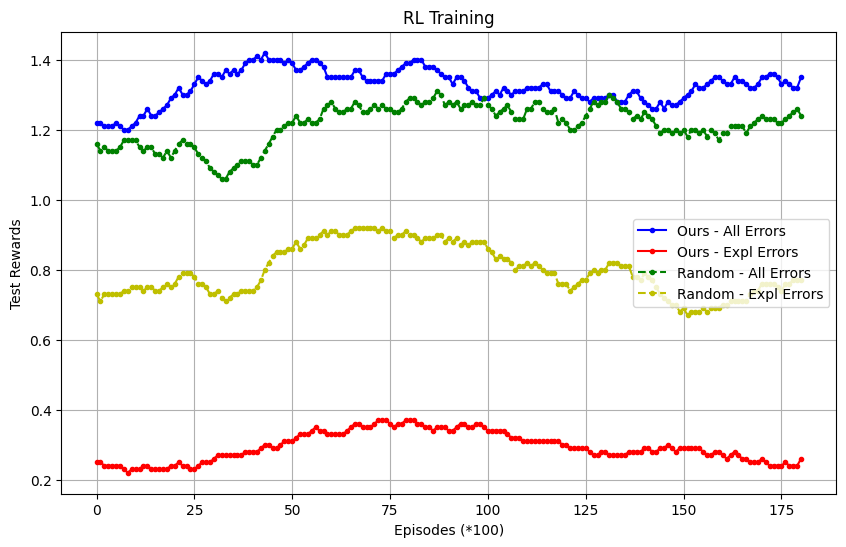

In [319]:
import pickle

with open('diversity_statistics_20steps.pkl', 'rb') as file:
    data = pickle.load(file)
# Extract every 1000th element
selected_elements = data["test_reward"]
selected_elements_expl = data["test_reward_expl"]


with open('random_diversity_statistics_20steps.pkl', 'rb') as file:
    data = pickle.load(file)
# Extract every 1000th element
random_selected_elements = data["test_reward"]
random_selected_elements_expl = data["test_reward_expl"]


window_size = 100
averages = []
averages_explain = []

random_averages = []
random_averages_explain = []

# Ensure the list is large enough
if len(random_selected_elements) >= window_size:
    for i in range(window_size, len(random_selected_elements) + 1):
        # Get the last 100 elements ending at index i
        window = selected_elements[i - window_size:i]
        average = sum(window) / window_size
        averages.append(average)
        
        window2 = selected_elements_expl[i - window_size:i]
        average2 = sum(window2) / window_size
        
        averages_explain.append(average2)

        window = random_selected_elements[i - window_size:i]
        average = sum(window) / window_size
        random_averages.append(average)
        
        window2 = random_selected_elements_expl[i - window_size:i]
        average2 = sum(window2) / window_size
        
        random_averages_explain.append(average2)
# Create corresponding x-axis values (iterations)
iterations = list(range(len(random_averages_explain)))

# Plot the selected elements
plt.figure(figsize=(10, 6))
plt.plot(iterations, averages, marker='.', linestyle='-', color='b', label='Ours - All Errors')
plt.plot(iterations, averages_explain, marker='.', linestyle='-', color='r', label='Ours - Expl Errors')
plt.plot(iterations, random_averages, marker='.', linestyle='--', color='g', label='Random - All Errors')
plt.plot(iterations, random_averages_explain, marker='.', linestyle='--', color='y', label='Random - Expl Errors')
plt.xlabel('Episodes (*100)')
plt.ylabel('Test Rewards')
plt.title('RL Training')
plt.legend()
plt.grid()
plt.show()

In [ ]:
env.action_space.contains(83)

In [ ]:
env.observation_space

In [7]:
import torch
import torch.nn as nn
from stable_baselines3 import DQN
from stable_baselines3.common.policies import BasePolicy

# Step 1: Define the Custom Q-Network
class StateActionQNetwork(nn.Module):
    def __init__(self, state_dim, action_dim, action_feature_dim):
        """
        Custom Q-network that incorporates state and action features.
        Args:
            state_dim (int): Dimension of the state space.
            action_dim (int): Number of discrete actions.
            action_feature_dim (int): Dimension of action feature space.
        """
        super(StateActionQNetwork, self).__init__()
        # State processing network
        self.state_net = nn.Sequential(
            nn.Linear(state_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
        )

        # Action feature embedding (for each action)
        self.action_embeddings = nn.Embedding(action_dim, action_feature_dim)

        # Combine state and action features
        self.q_net = nn.Sequential(
            nn.Linear(64 + action_feature_dim, 128),
            nn.ReLU(),
            nn.Linear(128, 1),  # Output a single Q-value for state-action pair
        )

    def forward(self, state, action):
        """
        Forward pass for the Q-network.
        Args:
            state (torch.Tensor): Batch of states (batch_size, state_dim).
            action (torch.Tensor): Batch of action indices (batch_size,).
        Returns:
            Q-values for the given state-action pairs (batch_size, 1).
        """
        state_features = self.state_net(state)  # Process state
        action_features = self.action_embeddings(action)  # Get action features
        combined = torch.cat([state_features, action_features], dim=1)  # Concatenate
        q_values = self.q_net(combined)  # Compute Q-values
        return q_values

# Step 2: Define a Custom Policy
class CustomStateActionPolicy(BasePolicy):
    def __init__(self, observation_space, action_space, lr_schedule, **kwargs):
        super(CustomStateActionPolicy, self).__init__(observation_space, action_space, lr_schedule, **kwargs)
        state_dim = observation_space.shape[0]
        action_dim = action_space.n
        action_feature_dim = 16  # Example: Embedding size for each action
        self.q_net = StateActionQNetwork(state_dim, action_dim, action_feature_dim)
        self.q_net_target = StateActionQNetwork(state_dim, action_dim, action_feature_dim)
        self.optimizer = torch.optim.Adam(self.parameters(), lr=lr_schedule(1))

    def forward(self, obs, deterministic=False):
        """
        Compute Q-values for all actions given a batch of states.
        Args:
            obs (torch.Tensor): Batch of states (batch_size, state_dim).
        Returns:
            Q-values for all actions (batch_size, action_dim).
        """
        batch_size = obs.shape[0]
        all_actions = torch.arange(self.action_space.n).expand(batch_size, -1).to(obs.device)
        print(all_actions)
        obs_repeated = obs.unsqueeze(1).expand(-1, self.action_space.n, -1)
        q_values = torch.stack([
            self.q_net(obs_repeated[:, i], all_actions[:, i])
            for i in range(self.action_space.n)
        ], dim=1).squeeze(-1)
        return q_values

    def _predict(self, obs, deterministic=False):
        """
        Select the action with the highest Q-value.
        """
        q_values = self.forward(obs)
        return torch.argmax(q_values, dim=1).cpu().numpy()

    def predict(self, observation, state=None, mask=None, deterministic=False):
        """
        Stable-Baselines3 required interface for prediction.
        """
        observation = torch.as_tensor(observation).float()
        return self._predict(observation, deterministic=deterministic), state


In [9]:
# Train the agent
gym.register(
    id="gymnasium_env/Auditing-v0",
    entry_point=AuditingEnv,
)

env = gym.make("gymnasium_env/Auditing-v0", state_shape=(n_classes, n_classes), action_list_length=len(X_test), target_list=target_list, dataset=y_proba)
env.reset()
mypolicy = CustomStateActionPolicy(env.observation_space, env.action_space)
# Instantiate and train the custom DQN
model = DQN(
    mypolicy,
    env,
    learning_rate=1e-3,
    buffer_size=5000,
    learning_starts=100,
    batch_size=32,
    gamma=0.99,
    verbose=1,
)

model.learn(total_timesteps=10000)

# Evaluate the trained model
from stable_baselines3.common.evaluation import evaluate_policy
mean_reward, std_reward = evaluate_policy(model, env, n_eval_episodes=10)
print(f"Mean reward: {mean_reward} ± {std_reward}")

/home/runai-home/.local/lib/python3.10/site-packages/gymnasium/envs/registration.py:642: UserWarning: WARN: Overriding environment gymnasium_env/Auditing-v0 already in registry.
  logger.warn(f"Overriding environment {new_spec.id} already in registry.")
/home/runai-home/.local/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:134: UserWarning: WARN: The obs returned by the `reset()` method was expecting numpy array dtype to be float32, actual type: float64
  logger.warn(
/home/runai-home/.local/lib/python3.10/site-packages/gymnasium/utils/passive_env_checker.py:158: UserWarning: WARN: The obs returned by the `reset()` method is not within the observation space.
  logger.warn(f"{pre} is not within the observation space.")


TypeError: CustomStateActionPolicy.__init__() missing 1 required positional argument: 'lr_schedule'